# 07 - PyTorch with TabNet

**TabNet** (Arik & Pfister, Google Cloud AI, 2019) is a deep learning model designed for tables. Instead of using all features at every step like an MLP, it works in several **decision steps**:
1. At each step an *attentive transformer* chooses which features to look at, using a **sparse mask** (sparsemax). Most features get a weight of exactly 0.
2. A *feature transformer* processes only the selected features.
3. The outputs of all steps are added up to give the prediction.

Because of the masks, TabNet can tell us which features it used, both overall and for each single prediction. This makes it one of the more transparent neural networks.

Main settings: `n_d`/`n_a` (width of the layers), `n_steps` (number of decision steps), `gamma` (how much a feature can be reused across steps), `lambda_sparse` (how strongly sparse masks are encouraged).

Implementation: `pytorch-tabnet` (DreamQuark). It supports several targets at once, so one model predicts 1M, 5Y and 30Y together.

In [1]:
import sys
import time
import warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pytorch_tabnet.tab_model import TabNetRegressor

from src import config, features, evaluate, plots

plots.setup()
pd.set_option("display.precision", 4)
df = features.load_dataset()

## 1. Model

In [2]:
def train_tabnet(X_train, y_train, X_val, y_val, n_d, n_steps, seed=config.SEED):
    model = TabNetRegressor(n_d=n_d, n_a=n_d, n_steps=n_steps, gamma=1.5, lambda_sparse=1e-4,
                            optimizer_params={"lr": 2e-2}, seed=seed, verbose=0, device_name="cpu")
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric=["rmse"],
              max_epochs=200, patience=30, batch_size=256, virtual_batch_size=64)
    return model


configs = [{"n_d": n_d, "n_steps": n_steps} for n_d in [8, 16] for n_steps in [3, 5]]
pd.DataFrame(configs)

,n_d,n_steps
0,8,3
1,8,5
2,16,3
3,16,5


## 2. Tuning on the validation set (seed 42)

In [3]:
best_config, tuning_rows = {}, []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, x_scaler, unscale_y = features.scale(data)
    (X_train, y_train), (X_val, y_val) = scaled["train"], scaled["val"]
    for cfg in configs:
        model = train_tabnet(X_train, y_train, X_val, y_val, **cfg)
        val_pred = evaluate.to_level(unscale_y(model.predict(X_val)), data["val"]["today"], mode)
        tuning_rows.append({"experiment": exp, **cfg, "best epoch": model.best_epoch,
                            "val RMSE (avg)": evaluate.average_rmse(data["val"]["future"], val_pred)})
    rows = [r for r in tuning_rows if r["experiment"] == exp]
    best = min(rows, key=lambda r: r["val RMSE (avg)"])
    best_config[exp] = {k: best[k] for k in ["n_d", "n_steps"]}
pd.DataFrame(tuning_rows)


Early stopping occurred at epoch 55 with best_epoch = 25 and best_val_0_rmse = 0.70007



Early stopping occurred at epoch 80 with best_epoch = 50 and best_val_0_rmse = 0.55554



Early stopping occurred at epoch 47 with best_epoch = 17 and best_val_0_rmse = 0.58252



Early stopping occurred at epoch 40 with best_epoch = 10 and best_val_0_rmse = 0.83577



Early stopping occurred at epoch 57 with best_epoch = 27 and best_val_0_rmse = 1.97714


...


Early stopping occurred at epoch 32 with best_epoch = 2 and best_val_0_rmse = 2.09041



Early stopping occurred at epoch 36 with best_epoch = 6 and best_val_0_rmse = 2.11761



Early stopping occurred at epoch 61 with best_epoch = 31 and best_val_0_rmse = 2.08919



Early stopping occurred at epoch 37 with best_epoch = 7 and best_val_0_rmse = 2.12072


,experiment,n_d,n_steps,best epoch,val RMSE (avg)
0,A,8,3,25,0.4489
1,A,8,5,50,0.3583
2,A,16,3,17,0.4056
3,A,16,5,10,0.5381
4,B,8,3,27,0.1551
5,B,8,5,45,0.1584
6,B,16,3,14,0.1565
7,B,16,5,16,0.1559
8,C,8,3,2,0.1615
9,C,8,5,6,0.1604


In [4]:
pd.DataFrame(best_config).T

,n_d,n_steps
A,8,5
B,8,3
C,16,3


## 3. Final models: 3 seeds per experiment

In [5]:
all_metrics, times = [], []
for exp in config.EXPERIMENTS:
    data, mode = features.get_experiment(df, exp)
    scaled, x_scaler, unscale_y = features.scale(data)
    (X_train, y_train), (X_val, y_val), (X_test, y_test) = scaled["train"], scaled["val"], scaled["test"]
    for seed in config.SEEDS:
        start = time.time()
        model = train_tabnet(X_train, y_train, X_val, y_val, seed=seed, **best_config[exp])
        if exp == "C":
            times.append(time.time() - start)
        pred_level = evaluate.to_level(unscale_y(model.predict(X_test)), data["test"]["today"], mode)
        evaluate.save_predictions("TabNet", exp, seed, data["test"], pred_level)
        m = evaluate.evaluate(data["test"]["future"], pred_level, data["test"]["today"])
        all_metrics.append(m.assign(experiment=exp, seed=seed).reset_index())
        if exp == "C" and seed == config.SEED:
            model_c, scaler_c, unscale_c, X_test_c = model, x_scaler, unscale_y, X_test

metrics = pd.concat(all_metrics)
summary = metrics.groupby(["experiment", "target"])[["RMSE", "MAE", "R2", "R2_change", "skill_vs_naive", "direction_acc"]]
order = ["1M", "5Y", "30Y"]
summary.mean().reindex(order, level=1).round(4)


Early stopping occurred at epoch 80 with best_epoch = 50 and best_val_0_rmse = 0.55554



Early stopping occurred at epoch 40 with best_epoch = 10 and best_val_0_rmse = 0.65211



Early stopping occurred at epoch 72 with best_epoch = 42 and best_val_0_rmse = 0.76002



Early stopping occurred at epoch 57 with best_epoch = 27 and best_val_0_rmse = 1.97714



Early stopping occurred at epoch 82 with best_epoch = 52 and best_val_0_rmse = 2.03948



Early stopping occurred at epoch 53 with best_epoch = 23 and best_val_0_rmse = 1.98099



Early stopping occurred at epoch 61 with best_epoch = 31 and best_val_0_rmse = 2.08919



Early stopping occurred at epoch 43 with best_epoch = 13 and best_val_0_rmse = 2.1601



Early stopping occurred at epoch 35 with best_epoch = 5 and best_val_0_rmse = 2.15823


RMSE     MAE      R2  R2_change  skill_vs_naive  \
experiment target                                                      
A          1M      1.2495  1.1469 -2.3776   -75.7667         -7.5097   
           5Y      0.5778  0.4692 -1.8163   -16.6701         -3.1899   
           30Y     0.7891  0.6715 -2.9475   -57.7022         -6.1044   
B          1M      0.1559  0.0818  0.9504    -0.1275         -0.0616   
           5Y      0.1429  0.1093  0.8285    -0.0761         -0.0360   
           30Y     0.1189  0.0931  0.9223    -0.1561         -0.0708   
C          1M      0.1806  0.0761  0.9334    -0.5147         -0.2302   
           5Y      0.1427  0.1087  0.8288    -0.0740         -0.0350   
           30Y     0.1226  0.0927  0.9174    -0.2278         -0.1034   

                   direction_acc  
experiment target                 
A          1M             0.5306  
           5Y             0.4726  
           30Y            0.4590  
B          1M             0.4943  
           5Y             0.4730  
           30Y            0.4957  
C          1M             0.5365  
           5Y             0.5119  
           30Y            0.4935

In [6]:
summary.std()[["RMSE", "skill_vs_naive"]].reindex(order, level=1).round(4)

RMSE  skill_vs_naive
experiment target                        
A          1M      0.3749          2.5532
           5Y      0.0459          0.3328
           30Y     0.3797          3.4186
B          1M      0.0037          0.0254
           5Y      0.0025          0.0181
           30Y     0.0040          0.0359
C          1M      0.0060          0.0407
           5Y      0.0030          0.0220
           30Y     0.0044          0.0400

In [7]:
evaluate.save_run_info("TabNet", {"train_seconds": float(np.mean(times)),
                                  "lines_of_code": evaluate.count_lines(train_tabnet),
                                  "hyperparameters": 10,
                                  "tuning_combinations": len(configs)})

**Observations**
- **Experiment A (level)** is TabNet's worst result and the worst of all frameworks: skill −7.5 (1M), −3.2 (5Y) and −6.1 (30Y). It also changes a lot between seeds (standard deviation of skill up to 3.4).
- **Experiment B is TabNet's best:** skill −0.06 (1M), −0.04 (5Y) and −0.07 (30Y). That's closer to naive than Keras or fastai in B, but still worse than naive.
- In **experiment C** the 5Y result is about the same (−0.035), but the 1M gets worse (−0.23).
- In B and C the results are fairly stable across seeds (standard deviation 0.02-0.04).
- Early stopping often picked a very early epoch (between 2 and 31) in the change experiments: after a few epochs there's nothing more to learn that also works on 2022.
- Direction accuracy is between 47% and 54%, about a coin flip.
- TabNet was the slowest framework to tune and train (about 5 minutes for the whole notebook on the CPU).

## 4. Training curve (experiment C, seed 42)

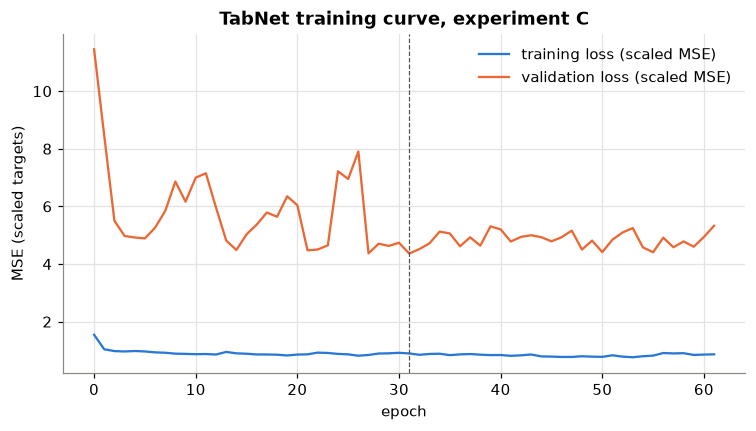

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(model_c.history["loss"], color=plots.BLUE, label="training loss (scaled MSE)")
ax.plot(np.array(model_c.history["val_0_rmse"]) ** 2, color=plots.ORANGE, label="validation loss (scaled MSE)")
ax.axvline(model_c.best_epoch, color="#52514e", linestyle="--", linewidth=0.8)
ax.set_xlabel("epoch")
ax.set_ylabel("MSE (scaled targets)")
ax.set_title("TabNet training curve, experiment C")
ax.legend()
plots.save(fig, "07_tabnet_training_curve")
plt.show()

## 5. Built-in explanations

### 5.1 Global feature importance
`feature_importances_` adds up how much each feature was selected by the masks across all decision steps, weighted by how much each step contributed to the output.

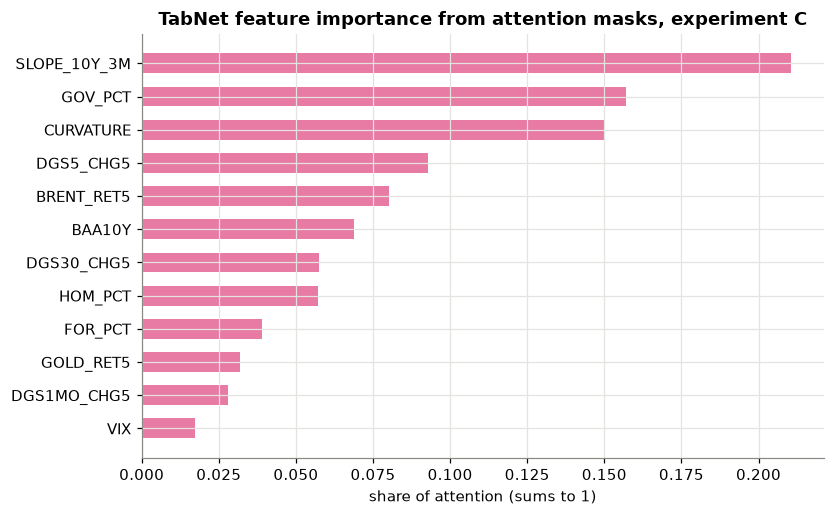

SLOPE_10Y_3M    0.211
GOV_PCT         0.157
CURVATURE       0.150
DGS5_CHG5       0.093
BRENT_RET5      0.080
BAA10Y          0.069
DGS30_CHG5      0.057
HOM_PCT         0.057
FOR_PCT         0.039
GOLD_RET5       0.032
DGS1MO_CHG5     0.028
VIX             0.017
SP500_RET5      0.007
DXY_RET5        0.001
SLOPE_10Y_2Y    0.001
dtype: float64

In [9]:
data_c, _ = features.get_experiment(df, "C")
importance = pd.Series(model_c.feature_importances_, index=features.NO_LEVEL_FEATURES).sort_values(ascending=False)
evaluate.save_importance("TabNet", importance, "mask_importance")

fig, ax = plt.subplots(figsize=(8, 5))
top = importance.head(12).iloc[::-1]
ax.barh(top.index, top.values, color=plots.MODEL_COLORS["TabNet"], height=0.6)
ax.set_xlabel("share of attention (sums to 1)")
ax.set_title("TabNet feature importance from attention masks, experiment C")
plots.save(fig, "07_tabnet_importance")
plt.show()
importance.round(3)

### 5.2 Which features did TabNet use on each day?

`explain()` gives the mask for every single prediction, so we can see which inputs the model used on each day. The heatmap shows the first 60 test days. Each column adds up to 1.

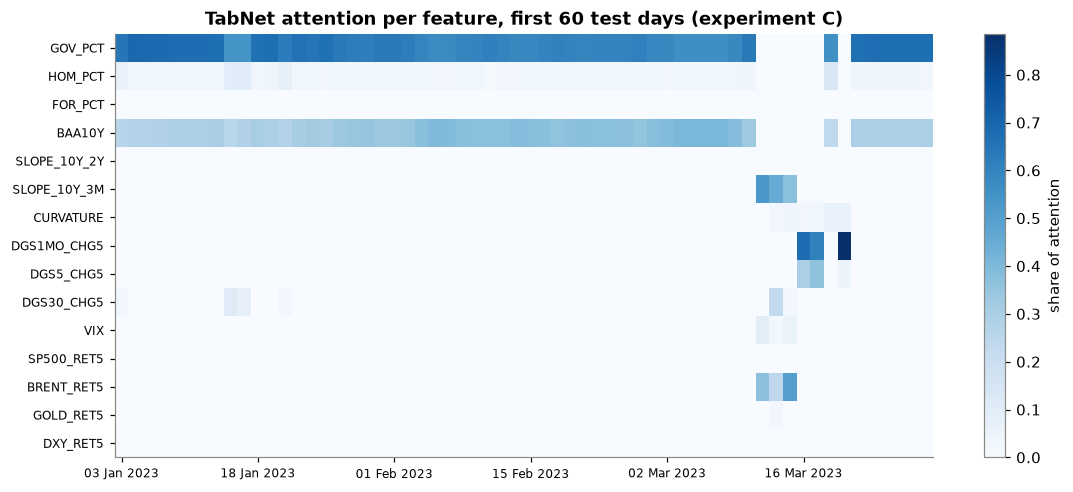

In [10]:
explain_matrix, masks = model_c.explain(X_test_c)
daily = pd.DataFrame(explain_matrix, index=data_c["test"]["X"].index, columns=features.NO_LEVEL_FEATURES)
daily = daily.div(daily.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 5))
first_days = daily.iloc[:60].T
im = ax.imshow(first_days.values, aspect="auto", cmap="Blues", vmin=0)
ax.set_yticks(range(len(first_days.index)))
ax.set_yticklabels(first_days.index, fontsize=8)
ax.set_xticks(range(0, 60, 10))
ax.set_xticklabels([d.strftime("%d %b %Y") for d in first_days.columns[::10]], fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="share of attention")
ax.set_title("TabNet attention per feature, first 60 test days (experiment C)")
plots.save(fig, "07_tabnet_masks")
plt.show()

**Observations**
- **Training curve:** the validation loss is very noisy and much higher than the training loss (2022 was a far more volatile year than 2010-2021). Early stopping kept epoch 31.
- **Global importance:** the 10Y-3M slope (21%), the Fed's share of the debt `GOV_PCT` (16%) and the curvature (15%) get the most attention. The dollar index return and the 10Y-2Y slope are almost never used, because sparsemax sets their weight to exactly 0. The 10Y-3M slope is also the top feature for linear regression and in XGBoost's SHAP plot.
- **Daily masks:** for most of January-March 2023, TabNet mainly looks at the slow-moving `GOV_PCT` and `BAA10Y`. Around **mid-March 2023**, when Silicon Valley Bank collapsed and yields fell sharply, its attention **switches** to the 10Y-3M slope, the recent changes of the 1M and 5Y yields, and oil returns.
- So TabNet changes which inputs it uses depending on market conditions, and its masks let us *see* this. A normal MLP (Keras, fastai, Flash) can't show this, which is TabNet's main advantage for **transparency**.